# Measuring the Incremental Sales Uplift from Shopper Media

## 1. Business motivation and research question

Retailers invest in shopper media to increase sales, but measuring its true impact (**how much additional revenue does shopper media actually generate?**) is challenging because media stores are selected rather than randomly assigned.

Product sales data also vary: established products have longer histories, new products have limited data, while expensive or infrequently purchased products may have many zero-sales weeks. These differences can affect the accuracy of incremental sales uplift measurement.

**Research question:** Which method measures shopper media's incremental sales uplift most accurately across different product and sales-data conditions?

The study compares four methods across three scenarios. It uses 100 newly generated datasets for each scenario and evaluates every estimate against the known true Average Treatment Effect on the Treated/Media Stores (ATT) in that dataset.

**Study setup**
- 200 stores: 50 media stores and 150 control stores.
- Media campaign: 4 weeks (weeks 25–28).
- Outcome: ATT Live, measured as additional sales in USD per media store per campaign week.
- Methods: 2 traditional approaches (Matching and Modern DiD), 2 machine-learning approaches (X-Learner and DRL (AIPW)).
- Evaluation: 100 new datasets per scenario using Monte Carlo simulation.

**Scenarios**
1. **Established product:** 24 weeks of pre-campaign sales.
2. **New product:** only 6 weeks of pre-campaign sales (weeks 19–24).
3. **Intermittent sales (Niche or high-priced product):** each store has zero sales in about 20%–50% of pre-campaign weeks; all media stores also have zero sales in 8 shared weeks and all control stores in 4 different shared weeks.


In [1]:
import warnings
import gc
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import StratifiedKFold
from IPython.display import display

SEED = 20261114
N_STORES, N_TREATED = 200, 50
N_CONTROL = N_STORES - N_TREATED
ALL_WEEKS = np.arange(1, 29)
PRE_WEEKS = np.arange(1, 25)
LIVE_WEEKS = np.arange(25, 29)

# Synthetic revenue calibration: one sales-index point represents $100.
INDEX_POINT_TO_USD = 100.0
THOUSAND_USD_TO_USD = 1000.0

SCENARIOS = {
    "normal": "Scenario 1: established product",
    "limited6": "Scenario 2: new product (6 pre-weeks)",
    "zeroheavy24": "Scenario 3: intermittent sales (store-specific + group-wide zero weeks)",
}
METHODS = ["Matching", "Modern DiD", "X-Learner", "DRL"]


## 2. Data and how methods are evaluated

For each scenario, the simulation generates 100 new datasets. Each replication creates new stores, media assignments, sales histories and campaign outcomes under the same scenario conditions. This is not a bootstrap of the original rows.

For every dataset, each method estimates ATT and its estimate is compared with that dataset's known true ATT. The results are summarised using three measures:

- **Bias – Does the method systematically overestimate or underestimate uplift?** A positive Bias means it overestimates ATT on average; a negative Bias means it underestimates. A value close to zero is better.
- **MAE (Mean Absolute Error) – How far are estimates from the true uplift on average?** It measures the average size of the error in USD, regardless of direction. Lower MAE is better.
- **RMSE (Root Mean Squared Error) – Does the method make some particularly large estimation errors?** It gives extra weight to large errors. Lower RMSE is better.


The box plot shows the spread of estimation errors across the 100 datasets. Errors closer to zero, with a narrower spread, indicate more stable estimates.


In [2]:
def zscore(x):
    x = pd.to_numeric(pd.Series(x), errors="coerce").to_numpy(dtype=float)
    if np.isnan(x).all():
        return np.zeros(len(x))
    med = np.nanmedian(x)
    x = np.where(np.isnan(x), med, x)
    sd = np.std(x)
    return (x - np.mean(x)) / sd if sd > 1e-10 else np.zeros(len(x))


def media_effect_profile(rng, hidden_priority, size, n_weeks=4):
    """Create heterogeneous media effects during the four live campaign weeks."""
    live_shape = np.array([0.94, 1.06, 1.10, 0.98])
    store_multiplier = np.clip(
        1.0 + 0.12 * hidden_priority + 0.10 * (size - 1.0) + rng.normal(0, 0.10, len(size)),
        0.62, 1.45
    )
    weekly_noise = rng.normal(0, 0.11, (len(size), n_weeks))
    weekly_noise = np.exp(weekly_noise - 0.5 * 0.11**2)
    return store_multiplier[:, None] * live_shape[None, :] * weekly_noise


def generate_scenario(scenario="normal", seed=SEED):
    """
    Generate 200 stores x 28 weeks with business-led, non-random media selection.
    normal: 24 pre-weeks of regular product sales.
    limited6: only 6 observed pre-weeks (weeks 19-24).
    zeroheavy24: 24 pre-weeks with store-specific zero-sales weeks (about 20%-50% per store), plus 8 group-wide zero-sales weeks for all media stores and 4 different group-wide zero-sales weeks for all control stores.
    """
    if scenario not in {"normal", "limited6", "zeroheavy24"}:
        raise ValueError("scenario must be 'normal', 'limited6' or 'zeroheavy24'")

    scenario_offset = {"normal": 0, "limited6": 101, "zeroheavy24": 202}[scenario]
    rng = np.random.default_rng(seed + scenario_offset)
    store_ids = np.array([f"Store_{i:03d}" for i in range(1, N_STORES + 1)])
    size = np.clip(rng.lognormal(0, 0.23, N_STORES), 0.55, 1.75)

    regions = np.array(["North", "Central", "South"])
    region = rng.choice(regions, N_STORES, p=[0.34, 0.31, 0.35])
    region_idx = np.array([int(np.where(regions == r)[0][0]) for r in region])
    footfall_base = np.maximum(100, 1050 * size + rng.normal(0, 95, N_STORES))
    category_base = np.maximum(40, 430 * size + rng.normal(0, 48, N_STORES))

    # Unobserved confounder: affects both selection and sales momentum; intentionally not a model feature.
    hidden_priority = rng.normal(0, 1, N_STORES)

    market_innov = rng.normal(0, 2.3, len(ALL_WEEKS))
    market = np.zeros(len(ALL_WEEKS))
    for w in range(1, len(ALL_WEEKS)):
        market[w] = 0.58 * market[w - 1] + market_innov[w]

    # Unobserved demand shocks load differently on stores with different latent priorities.
    priority_innov = rng.normal(0, 1.0, len(ALL_WEEKS))
    priority_demand_shock = np.zeros(len(ALL_WEEKS))
    for w in range(1, len(ALL_WEEKS)):
        priority_demand_shock[w] = 0.25 * priority_demand_shock[w - 1] + priority_innov[w]
    observed_pre_weeks = PRE_WEEKS if scenario != "limited6" else np.arange(19, 25)
    priority_demand_shock -= priority_demand_shock[observed_pre_weeks - 1].mean()

    region_shocks = np.zeros((len(regions), len(ALL_WEEKS)))
    for r in range(len(regions)):
        innovations_r = rng.normal(0, 2.35, len(ALL_WEEKS))
        for w in range(1, len(ALL_WEEKS)):
            region_shocks[r, w] = 0.42 * region_shocks[r, w - 1] + innovations_r[w]

    market_exposure = np.clip(1.0 + 0.42 * hidden_priority + rng.normal(0, 0.22, N_STORES), 0.40, 1.75)
    region_exposure = np.clip(rng.uniform(0.50, 1.55, N_STORES) + 0.10 * hidden_priority, 0.35, 1.75)
    trend_loading = 0.06
    store_trend = 0.06 + trend_loading * hidden_priority + rng.normal(0, 0.08, N_STORES)
    season_amplitude = np.clip(1.6 + 0.55 * size + rng.normal(0, 0.35, N_STORES), 0.6, 3.2)
    season_phase = rng.normal(0, 0.16, N_STORES)

    volatility = rng.uniform(0.80, 1.35, N_STORES)
    innovations = rng.normal(0, 5.2, (N_STORES, len(ALL_WEEKS))) * volatility[:, None]
    store_noise = np.zeros_like(innovations)
    store_noise[:, 0] = innovations[:, 0]
    for w in range(1, len(ALL_WEEKS)):
        store_noise[:, w] = 0.43 * store_noise[:, w - 1] + innovations[:, w]
    local_events = (rng.random((N_STORES, len(ALL_WEEKS))) < 0.04) * rng.normal(
        0, 6.0, (N_STORES, len(ALL_WEEKS))
    ) * volatility[:, None]

    sale_uniform = np.full((N_STORES, len(ALL_WEEKS)), np.nan)
    sale_probability = np.full((N_STORES, len(ALL_WEEKS)), np.nan)
    ticket_amount = np.full((N_STORES, len(ALL_WEEKS)), np.nan)
    ticket_mean_by_store = 5.0 * size

    rows = []
    for i, sid in enumerate(store_ids):
        for week in ALL_WEEKS:
            w = int(week)
            market_component = market_exposure[i] * market[w - 1]
            region_component = region_exposure[i] * region_shocks[region_idx[i], w - 1]
            season = season_amplitude[i] * np.sin(2 * np.pi * (w - 1) / 26 + season_phase[i])

            footfall = (
                footfall_base[i] + 2.0 * w + 13 * market_component
                + 7 * region_component + rng.normal(0, 34)
            )
            category = (
                category_base[i] + 0.18 * w + season + 1.2 * market_component
                + 0.8 * region_component + rng.normal(0, 17)
            )

            if scenario in {"normal", "limited6"}:
                if scenario == "limited6" and w < 19:
                    sales = np.nan
                    available = False
                else:
                    baseline = 88.0 if scenario == "normal" else 80.0
                    trend_center = 12.5 if scenario == "normal" else 22.5
                    sales = (
                        baseline * size[i] + store_trend[i] * (w - trend_center) + season
                        + 0.95 * market_component + 1.05 * region_component
                        + 1.30 * hidden_priority[i] * priority_demand_shock[w - 1]
                        + store_noise[i, w - 1] + local_events[i, w - 1]
                        + rng.normal(0, 4.0 * volatility[i])
                    )
                    sales = max(0.0, float(sales))
                    available = True
                unit = "USD revenue"
            else:
                unit = "USD revenue"
                if w <= 24:
                    # Start with positive store-week sales. Group-wide zero weeks
                    # are imposed after media/control assignment below.
                    ticket = ticket_mean_by_store[i] * np.exp(rng.normal(-0.5 * 0.32**2, 0.32))
                    sales = float(ticket)
                    available = True
                else:
                    p0 = np.clip(
                        0.50 + 0.045 * (size[i] - 1.0)
                        + 0.025 * hidden_priority[i]
                        + 0.018 * np.tanh(market_component / 4.0)
                        + 0.018 * np.tanh(region_component / 4.0),
                        0.30, 0.70
                    )
                    u_sale = rng.random()
                    ticket = ticket_mean_by_store[i] * np.exp(rng.normal(-0.5 * 0.38**2, 0.38))
                    sale_uniform[i, w - 1] = u_sale
                    sale_probability[i, w - 1] = p0
                    ticket_amount[i, w - 1] = ticket
                    sales = float(ticket) if u_sale < p0 else 0.0
                    available = True

            rows.append({
                "Store_ID": sid, "Week": w, "Sales": sales,
                "Store_Size": float(size[i]), "Region": region[i],
                "Footfall": float(footfall), "Category_Sales": float(category),
                "Product_Available": int(available), "True_Media_Effect": 0.0
            })

    panel = pd.DataFrame(rows)

    # Business-led selection: balanced across store-size tiers but not randomized.
    pre = panel.loc[panel["Week"].isin(PRE_WEEKS) & panel["Sales"].notna()]
    pre_sales = pre.groupby("Store_ID")["Sales"].agg(["mean", "std", lambda x: (x == 0).mean()])
    pre_sales.columns = ["pre_mean", "pre_sd", "pre_zero"]
    pre_store_panel = panel.loc[panel["Week"].isin(PRE_WEEKS)]
    store = pre_store_panel.groupby("Store_ID").agg(
        Store_Size=("Store_Size", "first"), Region=("Region", "first"),
        Footfall_Pre=("Footfall", "mean"), Category_Pre=("Category_Sales", "mean")
    ).join(pre_sales).reindex(store_ids)
    size_eff = store["Store_Size"]
    foot_eff = store["Footfall_Pre"] - 1050 * size_eff
    cat_eff = store["Category_Pre"] - 430 * size_eff
    score = (
        0.12 * zscore(foot_eff) + 0.10 * zscore(cat_eff)
        - 0.45 * zscore(store["pre_mean"])
        + 1.00 * hidden_priority + rng.normal(0, 1.0, N_STORES)
    )
    tiers = pd.qcut(store["Store_Size"], q=4, labels=False, duplicates="drop").to_numpy()
    quotas = [10, 12, 13, 15]
    selected = []
    for tier, quota in enumerate(quotas):
        eligible = np.where(tiers == tier)[0]
        selected.extend(eligible[np.argsort(score[eligible])[-quota:]].tolist())
    treated = np.zeros(N_STORES, dtype=int)
    treated[np.array(selected, dtype=int)] = 1
    tmap = dict(zip(store_ids, treated))
    panel["Treated"] = panel["Store_ID"].map(tmap).astype(int)

    if scenario == "zeroheavy24":
        # Group-wide zero-sales weeks:
        # - all media stores are zero in 8 shared pre-campaign weeks;
        # - all control stores are zero in 4 different shared weeks.
        media_zero_weeks = set(
            rng.choice(PRE_WEEKS, size=8, replace=False).tolist()
        )
        available_control_weeks = np.array(
            sorted(set(PRE_WEEKS.tolist()) - media_zero_weeks)
        )
        control_zero_weeks = set(
            rng.choice(available_control_weeks, size=4, replace=False).tolist()
        )

        media_zero_mask = (
            panel["Treated"].eq(1) & panel["Week"].isin(media_zero_weeks)
        )
        control_zero_mask = (
            panel["Treated"].eq(0) & panel["Week"].isin(control_zero_weeks)
        )
        panel.loc[media_zero_mask, "Sales"] = 0.0
        panel.loc[control_zero_mask, "Sales"] = 0.0

        # Add store-specific zero-sales weeks. Total zero weeks per store are
        # randomly set between 5 and 12 of 24 (about 20%-50%). The shared
        # group-wide weeks count toward each store's total.
        for store_id in store_ids:
            is_media = int(tmap[store_id]) == 1
            shared_weeks = media_zero_weeks if is_media else control_zero_weeks
            minimum_total = len(shared_weeks)
            target_total = int(rng.integers(max(5, minimum_total), 13))
            additional_count = target_total - minimum_total
            candidate_weeks = np.array(
                sorted(set(PRE_WEEKS.tolist()) - shared_weeks)
            )
            individual_zero_weeks = set(
                rng.choice(candidate_weeks, size=additional_count, replace=False).tolist()
            ) if additional_count > 0 else set()

            individual_mask = (
                panel["Store_ID"].eq(store_id)
                & panel["Week"].isin(individual_zero_weeks)
            )
            panel.loc[individual_mask, "Sales"] = 0.0

    # Media effect varies by store and week during the four live campaign weeks.
    profile = media_effect_profile(rng, hidden_priority, size, n_weeks=4)
    for week in LIVE_WEEKS:
        j = int(week - 25)
        week_mask = panel["Week"].eq(int(week))
        row_indices = panel.index[week_mask]
        ids = panel.loc[week_mask, "Store_ID"].str.extract(r"(\d+)")[0].astype(int).to_numpy() - 1
        is_treated = panel.loc[week_mask, "Treated"].to_numpy().astype(bool)

        if scenario in {"normal", "limited6"}:
            effect_by_store = 14.0 * profile[:, j]
            for row_idx, store_idx, is_t in zip(row_indices, ids, is_treated):
                if is_t:
                    effect = float(effect_by_store[store_idx])
                    panel.at[row_idx, "Sales"] = max(0.0, panel.at[row_idx, "Sales"] + effect)
                    panel.at[row_idx, "True_Media_Effect"] = effect
        else:
            # Media increases the chance of a purchase during the live campaign.
            delta_p_by_store = np.clip(0.16 * profile[:, j], 0.01, 0.28)
            for row_idx, store_idx, is_t in zip(row_indices, ids, is_treated):
                if is_t:
                    delta_p = float(delta_p_by_store[store_idx])
                    p0 = float(sale_probability[store_idx, week - 1])
                    u_sale = float(sale_uniform[store_idx, week - 1])
                    ticket = float(ticket_amount[store_idx, week - 1])
                    panel.at[row_idx, "Sales"] = ticket if u_sale < min(0.98, p0 + delta_p) else 0.0
                    panel.at[row_idx, "True_Media_Effect"] = delta_p * ticket_mean_by_store[store_idx]

    # Put all scenarios on the same USD scale.
    # Scenarios 1–2 start from a synthetic sales index; use the stated
    # illustrative calibration of $100 per index point.
    # Scenario 3 was generated in $000, so convert it to dollars.
    if scenario in {"normal", "limited6"}:
        panel["Sales"] = panel["Sales"] * INDEX_POINT_TO_USD
        panel["True_Media_Effect"] = panel["True_Media_Effect"] * INDEX_POINT_TO_USD
    else:
        panel["Sales"] = panel["Sales"] * THOUSAND_USD_TO_USD
        panel["True_Media_Effect"] = panel["True_Media_Effect"] * THOUSAND_USD_TO_USD

    panel["Post"] = (panel["Week"] >= 25).astype(int)
    panel["Treated_Post"] = panel["Treated"] * panel["Post"]
    panel["Scenario"] = scenario

    treated_effects = panel.loc[panel["Treated"].eq(1)]
    truth = {
        "live": float(treated_effects.loc[treated_effects["Week"].isin(LIVE_WEEKS), "True_Media_Effect"].mean()),
            }
    return panel, truth, unit


def store_summary(panel):
    pre = panel.loc[panel["Week"].isin(PRE_WEEKS) & panel["Sales"].notna()].copy()
    live = panel.loc[panel["Week"].isin(LIVE_WEEKS) & panel["Sales"].notna()].copy()

    p = pre.groupby("Store_ID").agg(
        Pre_Mean=("Sales", "mean"), Pre_SD=("Sales", "std"),
        Pre_Zero_Rate=("Sales", lambda x: float((x == 0).mean())), Pre_N=("Sales", "count")
    )
    slopes = {}
    for sid, g in pre.groupby("Store_ID"):
        slopes[sid] = float(np.polyfit(g["Week"], g["Sales"], 1)[0]) if len(g) >= 2 else np.nan
    p["Pre_Slope"] = pd.Series(slopes)

    q_live = live.groupby("Store_ID").agg(Live_Mean=("Sales", "mean"))
    pre_info = panel.loc[panel["Week"].isin(PRE_WEEKS)].groupby("Store_ID").agg(
        Treated=("Treated", "first"), Store_Size=("Store_Size", "first"),
        Region=("Region", "first"), Footfall_Pre=("Footfall", "mean"),
        Category_Pre=("Category_Sales", "mean")
    )
    s = pre_info.join(p).join(q_live).reset_index()
    s["Pre_N"] = s["Pre_N"].fillna(0)
    s["Has_Pre_History"] = (s["Pre_N"] > 0).astype(int)
    s["Delta_Live"] = s["Live_Mean"] - s["Pre_Mean"]

    for col in ["Pre_Mean", "Pre_SD", "Pre_Zero_Rate", "Pre_Slope"]:
        s[col + "_Missing"] = s[col].isna().astype(int)
        s[col] = s[col].fillna(s[col].median() if s[col].notna().any() else 0.0)
    return s


def feature_matrix(summary):
    numeric = summary[[
        "Store_Size", "Footfall_Pre", "Category_Pre", "Pre_Mean", "Pre_SD",
        "Pre_Zero_Rate", "Pre_Slope", "Pre_N", "Has_Pre_History",
        "Pre_Mean_Missing", "Pre_SD_Missing", "Pre_Slope_Missing"
    ]].astype(float)
    dummies = pd.get_dummies(summary["Region"], prefix="Region", drop_first=True, dtype=float)
    x = pd.concat([numeric, dummies], axis=1).replace([np.inf, -np.inf], np.nan)
    x = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(x), columns=x.columns, index=x.index)
    return x

## 3. Measurement methods

All four methods estimate **ATT Live** (the average additional sales per media store per campaign week):

- **Matching:** Compare media stores with similar control stores.
  1. Find similar stores: Match each media store with 1–5 similar control stores based on historical sales and store characteristics.
  2. Estimate counterfactual: Use matched control stores to predict sales without media.
  3. Measure uplift: Subtract predicted sales from actual sales and average across media stores.

- **Modern DiD:** Predict what media-store sales would have been without the campaign.
  1. Fit a model: Use untreated observations to estimate store effects and common weekly effects.
  2. Predict counterfactual: Estimate media-store sales during the campaign without media.
  3. Measure uplift: Compare actual sales with predicted sales and average the differences.

- **X-Learner:** Use machine learning to estimate the media effect for each store.
  1. Train sales models: Build separate sales prediction models for media and control stores.
  2. Estimate individual effects: Predict missing outcomes and train models to estimate store-level media effects.
  3. Combine and average: Use propensity scores to combine effect predictions and calculate ATT.


- **DRL (AIPW):** Combine media-selection and sales prediction models to estimate uplift.
  1. Build two models: Predict the probability of a store receiving media and its expected sales.
  2. Correct predictions: Combine predicted effects with adjustments based on actual sales and prediction errors.
  3. Measure uplift: Average the corrected treatment effects across media stores.


In [3]:
def matching_att(summary, k=3):
    """Match each media store to its 3 nearest control stores, with replacement."""
    x = feature_matrix(summary)
    t = summary["Treated"].to_numpy()
    treated_idx, control_idx = np.where(t == 1)[0], np.where(t == 0)[0]

    scaled = StandardScaler().fit(x.iloc[control_idx]).transform(x)
    nearest = np.argsort(cdist(scaled[treated_idx], scaled[control_idx]), axis=1)[:, :k]

    live = summary["Live_Mean"].to_numpy()
    differences = live[treated_idx] - live[control_idx][nearest].mean(axis=1)

    def max_smd(a, b):
        pooled = np.sqrt((a.var(axis=0, ddof=1) + b.var(axis=0, ddof=1)) / 2)
        pooled = np.where(pooled < 1e-8, 1.0, pooled)
        return float(np.max(np.abs(a.mean(axis=0) - b.mean(axis=0)) / pooled))

    values = x.to_numpy(float)
    balance = {
        "before": max_smd(values[treated_idx], values[control_idx]),
        "after": max_smd(
            values[treated_idx],
            values[control_idx][nearest].reshape(-1, values.shape[1])
        )
    }
    return float(differences.mean()), balance



def modern_did_att(panel):
    """
    Two-stage Modern DiD (Gardner-style).

    Stage 1 estimates untreated sales using store fixed effects, week fixed effects,
    and category sales, using only observations without media.
    Stage 2 averages the treated stores' residual sales during weeks 25–28.
    Sparse least squares keeps the fixed-effects calculation fast.
    """
    from scipy.sparse import csr_matrix, hstack
    from scipy.sparse.linalg import lsqr

    data = panel.loc[panel["Sales"].notna()].copy().reset_index(drop=True)
    treated_post = (
        (data["Treated"].to_numpy() == 1)
        & (data["Week"].to_numpy() >= 25)
    )
    train_idx = np.flatnonzero(~treated_post)
    all_idx = np.arange(len(data))

    stores = sorted(data["Store_ID"].unique())
    weeks = sorted(data["Week"].unique())
    store_codes = pd.Categorical(data["Store_ID"], categories=stores).codes
    week_codes = pd.Categorical(data["Week"], categories=weeks).codes
    n_stores, n_weeks = len(stores), len(weeks)

    def make_design(indices):
        n = len(indices)
        rows = np.arange(n)
        store_dummies = csr_matrix(
            (np.ones(n), (rows, store_codes[indices])),
            shape=(n, n_stores)
        )[:, 1:]
        week_dummies = csr_matrix(
            (np.ones(n), (rows, week_codes[indices])),
            shape=(n, n_weeks)
        )[:, 1:]
        intercept = csr_matrix(np.ones((n, 1)))
        category_sales = csr_matrix(
            data["Category_Sales"].to_numpy()[indices].reshape(-1, 1)
        )
        return hstack(
            [intercept, store_dummies, week_dummies, category_sales],
            format="csr"
        )

    x_train = make_design(train_idx)
    coefficients = lsqr(
        x_train,
        data["Sales"].to_numpy()[train_idx],
        atol=1e-8,
        btol=1e-8,
        iter_lim=1000
    )[0]

    predicted_without_media = make_design(all_idx) @ coefficients
    residuals = data["Sales"].to_numpy()[treated_post] - predicted_without_media[treated_post]
    return float(np.mean(residuals))


def drl_core(x, y, t, seed=SEED):
    """Cross-fitted AIPW estimator for ATT."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    t = np.asarray(t, dtype=int)

    n_splits = min(2, int(np.bincount(t).min()))
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    propensity = np.zeros(len(y))
    outcome_control = np.zeros(len(y))

    for fold, (train_idx, test_idx) in enumerate(cv.split(x, t)):
        propensity_model = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=0.5, max_iter=2000)
        )
        propensity_model.fit(x[train_idx], t[train_idx])
        propensity[test_idx] = propensity_model.predict_proba(x[test_idx])[:, 1]

        control_train = train_idx[t[train_idx] == 0]
        outcome_model = make_pipeline(
            StandardScaler(),
            RandomForestRegressor(
                n_estimators=8, min_samples_leaf=5, max_features=0.85,
                random_state=seed + fold, n_jobs=1
            )
        )
        outcome_model.fit(x[control_train], y[control_train])
        outcome_control[test_idx] = outcome_model.predict(x[test_idx])

    propensity = np.clip(propensity, 0.03, 0.97)
    treated_idx, control_idx = np.where(t == 1)[0], np.where(t == 0)[0]
    weights = propensity[control_idx] / (1 - propensity[control_idx])
    weights = weights / weights.sum()

    treated_residual = y[treated_idx] - outcome_control[treated_idx]
    control_residual = y[control_idx] - outcome_control[control_idx]
    adjustment = float(np.sum(weights * control_residual))

    estimate = float(np.mean(treated_residual) - adjustment)
    return estimate


def xlearner_core(x, y, t, seed=SEED):
    """Cross-fitted X-Learner with random-forest outcome and effect models."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    t = np.asarray(t, dtype=int)

    n_splits = min(2, int(np.bincount(t).min()))
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    m0_oof = np.zeros(len(y))
    m1_oof = np.zeros(len(y))

    for fold, (train_idx, test_idx) in enumerate(cv.split(x, t)):
        train_control = train_idx[t[train_idx] == 0]
        train_treated = train_idx[t[train_idx] == 1]

        model0 = RandomForestRegressor(
            n_estimators=10, min_samples_leaf=5, max_features=0.85,
            random_state=seed + fold, n_jobs=1
        )
        model1 = RandomForestRegressor(
            n_estimators=8, min_samples_leaf=4, max_features=0.85,
            random_state=seed + 100 + fold, n_jobs=1
        )
        model0.fit(x[train_control], y[train_control])
        model1.fit(x[train_treated], y[train_treated])
        m0_oof[test_idx] = model0.predict(x[test_idx])
        m1_oof[test_idx] = model1.predict(x[test_idx])

    treated_idx, control_idx = np.where(t == 1)[0], np.where(t == 0)[0]
    d1 = y[treated_idx] - m0_oof[treated_idx]
    d0 = m1_oof[control_idx] - y[control_idx]

    tau1 = RandomForestRegressor(
        n_estimators=8, max_depth=3, min_samples_leaf=4,
        random_state=seed + 201, n_jobs=1
    )
    tau0 = RandomForestRegressor(
        n_estimators=8, max_depth=3, min_samples_leaf=5,
        random_state=seed + 202, n_jobs=1
    )
    tau1.fit(x[treated_idx], d1)
    tau0.fit(x[control_idx], d0)

    propensity_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=0.5, max_iter=2000)
    )
    propensity_model.fit(x, t)
    propensity_treated = np.clip(
        propensity_model.predict_proba(x[treated_idx])[:, 1], 0.03, 0.97
    )

    tau_treated = (
        propensity_treated * tau0.predict(x[treated_idx])
        + (1 - propensity_treated) * tau1.predict(x[treated_idx])
    )
    return float(np.mean(tau_treated))


def estimate_all(panel, seed=SEED):
    """Run all four methods and return ATT Live estimates plus matching diagnostics."""
    summary = store_summary(panel)
    x = feature_matrix(summary).to_numpy(float)
    y = summary["Delta_Live"].to_numpy(float)
    treated = summary["Treated"].to_numpy(int)

    matching_estimate, balance = matching_att(summary)
    estimates = {
        "Matching": matching_estimate,
        "Modern DiD": modern_did_att(panel),
        "X-Learner": xlearner_core(x, y, treated, seed + 20),
        "DRL": drl_core(x, y, treated, seed + 10),
    }
    return estimates, balance, summary


In [4]:
N_REPS_MC = 100

def run_monte_carlo_scenario(key, n_reps=N_REPS_MC):
    """
    Robustness evaluation using 100 newly generated datasets per scenario.

    Every replication regenerates store characteristics, non-random media
    assignment, unobserved confounding, sales history, and store-level media
    effects under the same scenario design. It does not bootstrap rows or keep
    the reference stores fixed. Each estimate is compared with that replication's
    own known ATT.
    """
    scenario_index = list(SCENARIOS).index(key)
    rows = []

    for rep in range(n_reps):
        dataset_seed = SEED + 100_000 + scenario_index * 10_000 + rep
        method_seed = SEED + 200_000 + scenario_index * 10_000 + rep

        new_panel, new_truth, unit = generate_scenario(key, seed=dataset_seed)

        # Check that each generated dataset preserves the requested scenario.
        if key == "limited6":
            pre_counts = (
                new_panel.loc[new_panel["Week"].isin(PRE_WEEKS)]
                .groupby("Store_ID")["Sales"].count()
            )
            assert pre_counts.eq(6).all()

        if key == "zeroheavy24":
            pre = new_panel.loc[new_panel["Week"].isin(PRE_WEEKS)].copy()
            group_zero = (
                pre.assign(IsZero=pre["Sales"].eq(0))
                .groupby(["Week", "Treated"])["IsZero"].all()
                .unstack()
            )
            media_group_zero = int(group_zero[1].sum())
            control_group_zero = int(group_zero[0].sum())
            store_zero_share = pre.groupby("Store_ID")["Sales"].apply(
                lambda values: float(values.eq(0).mean())
            )
            assert media_group_zero == 8
            assert control_group_zero == 4
            assert store_zero_share.between(0.20, 0.50).all()

        # Hide the known effect from the estimators.
        observed = new_panel.drop(
            columns=["True_Media_Effect", "Scenario"], errors="ignore"
        ).copy()
        estimates, _, _ = estimate_all(observed, seed=method_seed)
        true_att = float(new_truth["live"])

        for method in METHODS:
            estimate = float(estimates[method])
            rows.append({
                "Replication": rep + 1,
                "Method": method,
                "Estimate": estimate,
                "True_ATT": true_att,
                "Error": estimate - true_att,
            })

        del new_panel, observed, estimates
        if (rep + 1) % 25 == 0:
            gc.collect()

    results = pd.DataFrame(rows)
    summary = (
        results.groupby("Method")
        .agg(
            Bias=("Error", "mean"),
            MAE=("Error", lambda values: np.mean(np.abs(values))),
            RMSE=("Error", lambda values: np.sqrt(np.mean(np.square(values)))),
        )
        .reindex(METHODS)
        .reset_index()
        .sort_values(["MAE", "RMSE"])
        .reset_index(drop=True)
    )

    print(
        f"Robustness evaluation — {SCENARIOS[key]}: "
        f"{n_reps} newly generated datasets"
    )
    print(
        "Each replication regenerates all 200 stores and compares each method "
        "with that dataset's own known ATT. Lower MAE/RMSE is better; Bias "
        "closer to zero is better."
    )
    mean_true_att = float(results["True_ATT"].mean())
    print(
        f"Average true ATT across the {n_reps} datasets: "
        f"${mean_true_att:,.2f} per media store per campaign week."
    )
    display(summary.round(2))

    fig, ax = plt.subplots(figsize=(8.5, 4.3))
    box_data = [
        results.loc[results["Method"].eq(method), "Error"].to_numpy()
        for method in METHODS
    ]
    ax.boxplot(box_data, tick_labels=METHODS, showmeans=True)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.2)
    ax.set_title(f"ATT error across {n_reps} new datasets — {SCENARIOS[key]}")
    ax.set_ylabel("Estimated ATT − true ATT (USD/store/week)")
    ax.set_xlabel("Measurement method")
    ax.grid(axis="y", alpha=0.22)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    return results, summary


## 4. Scenario 1 — Established product

**Business situation:** The product has 24 weeks of pre-campaign sales history.

Run 100 newly generated datasets under this scenario. Compare the four methods using Bias, MAE and RMSE. The box plot shows the distribution of ATT estimation errors across replications.


Robustness evaluation — Scenario 1: established product: 100 newly generated datasets
Each replication regenerates all 200 stores and compares each method with that dataset's own known ATT. Lower MAE/RMSE is better; Bias closer to zero is better.
Average true ATT across the 100 datasets: $1,579.44 per media store per campaign week.


,Method,Bias,MAE,RMSE
0,DRL,80.63,120.90,159.39
1,X-Learner,79.01,125.50,155.94
2,Modern DiD,102.84,142.88,177.35
3,Matching,101.82,149.80,184.03


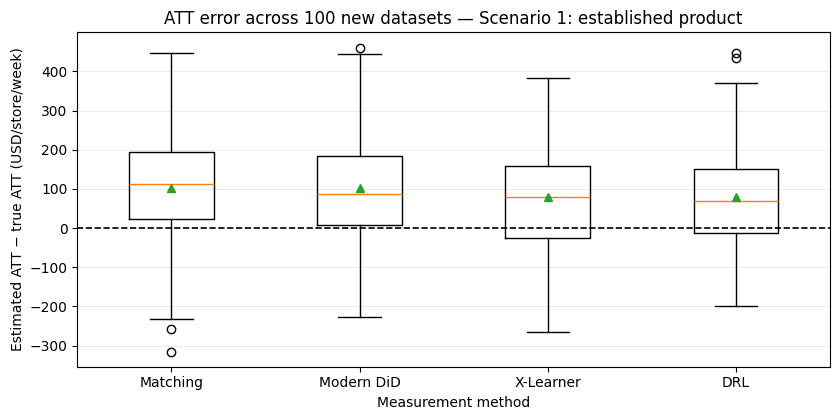

In [5]:
scenario1_mc_results, scenario1_mc_summary = run_monte_carlo_scenario("normal")


## 5. Scenario 2 — New product

**Business situation:** Only 6 weeks of pre-campaign sales history are available (weeks 19–24).

Run 100 newly generated datasets under this scenario. Compare the four methods using Bias, MAE and RMSE. The box plot shows the distribution of ATT estimation errors across replications.


Robustness evaluation — Scenario 2: new product (6 pre-weeks): 100 newly generated datasets
Each replication regenerates all 200 stores and compares each method with that dataset's own known ATT. Lower MAE/RMSE is better; Bias closer to zero is better.
Average true ATT across the 100 datasets: $1,580.44 per media store per campaign week.


,Method,Bias,MAE,RMSE
0,Matching,70.02,168.75,206.19
1,DRL,70.63,174.56,207.53
2,X-Learner,95.54,184.05,215.57
3,Modern DiD,101.10,189.31,220.47


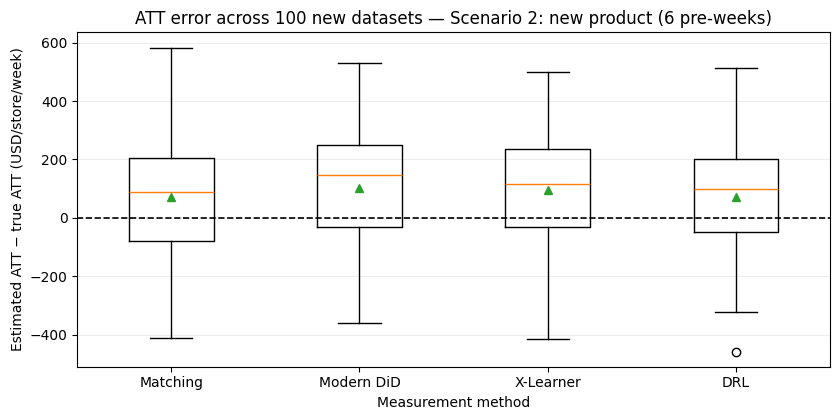

In [6]:
scenario2_mc_results, scenario2_mc_summary = run_monte_carlo_scenario("limited6")


## 6. Scenario 3 — Intermittent sales

**Business situation:** Each store has zero sales in approximately 20%–50% of its 24 pre-campaign weeks. In addition, all 50 media stores have zero sales in 8 shared weeks, while all 150 control stores have zero sales in 4 different shared weeks.

This scenario represents irregular purchasing patterns, which may occur for higher-priced or infrequently purchased products. Product price itself is not separately simulated.

Run 100 newly generated datasets under this scenario. Compare the four methods using Bias, MAE and RMSE. The box plot shows the distribution of ATT estimation errors across replications.


Robustness evaluation — Scenario 3: intermittent sales (store-specific + group-wide zero weeks): 100 newly generated datasets
Each replication regenerates all 200 stores and compares each method with that dataset's own known ATT. Lower MAE/RMSE is better; Bias closer to zero is better.
Average true ATT across the 100 datasets: $942.18 per media store per campaign week.


,Method,Bias,MAE,RMSE
0,X-Learner,146.35,287.75,363.82
1,Matching,174.22,319.43,397.75
2,DRL,94.71,395.87,504.29
3,Modern DiD,470.18,478.08,540.56


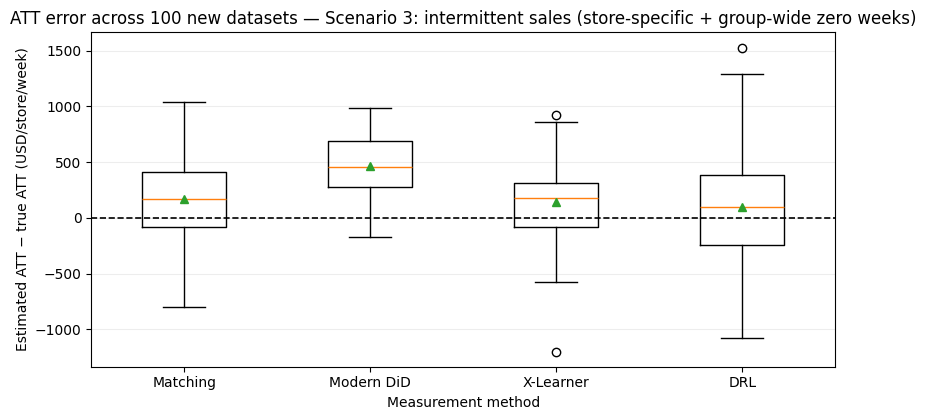

In [7]:
scenario3_mc_results, scenario3_mc_summary = run_monte_carlo_scenario("zeroheavy24")


## 7. Conclusion and key takeaways

The conclusions below use only the 100-replication Monte Carlo results for each scenario. The preferred method is the one with the lowest MAE. Bias shows whether estimates tend to be too high or too low, while RMSE shows sensitivity to large errors.


In [8]:
scenario_mc = {
    "Scenario 1 — Established product": scenario1_mc_results,
    "Scenario 2 — New product (6 pre-weeks)": scenario2_mc_results,
    "Scenario 3 — Intermittent sales": scenario3_mc_results,
}

summary_by_scenario = {
    "Scenario 1 — Established product": scenario1_mc_summary,
    "Scenario 2 — New product (6 pre-weeks)": scenario2_mc_summary,
    "Scenario 3 — Intermittent sales": scenario3_mc_summary,
}

conclusion_rows = []
for scenario_name, results in scenario_mc.items():
    summary = summary_by_scenario[scenario_name].sort_values(["MAE", "RMSE"])
    best = summary.iloc[0]
    conclusion_rows.append({
        "Scenario": scenario_name,
        "Average true ATT ($)": results["True_ATT"].mean(),
        "Best method": best["Method"],
        "Bias ($)": best["Bias"],
        "MAE ($)": best["MAE"],
        "RMSE ($)": best["RMSE"],
    })

conclusion_table = pd.DataFrame(conclusion_rows)
print("Monte Carlo comparison — 100 newly generated datasets per scenario")
display(conclusion_table.round(2))



Monte Carlo comparison — 100 newly generated datasets per scenario


,Scenario,Average true ATT ($),Best method,Bias ($),MAE ($),RMSE ($)
0,Scenario 1 — Established product,1579.44,DRL,80.63,120.90,159.39
1,Scenario 2 — New product (6 pre-weeks),1580.44,Matching,70.02,168.75,206.19
2,Scenario 3 — Intermittent sales,942.18,X-Learner,146.35,287.75,363.82


**Findings:**

Scenario 1 – Established product: DRL achieves the lowest MAE, potentially benefiting from more historical information to model store characteristics, media selection and sales outcomes. Its relatively low error suggests that uplift can be estimated more accurately when sales histories are sufficiently available.

Scenario 2 – New product: Matching performs best. With only six weeks of pre-campaign data, finding comparable control stores may work better than relying heavily on historical trends or more complex predictive models in this simulation.

Scenario 3 – Intermittent sales: X-Learner performs best, potentially because its flexible outcome and treatment-effect models can capture differences between stores. However, its MAE is substantially higher, indicating that frequent zero-sales observations make uplift estimation more challenging.

**Business takeaways:**
  1. No single method performs best in every scenario. Measurement accuracy depends on product characteristics and data availability.
  2. Historical sales data improve measurement opportunities. Limited history and irregular sales patterns can make counterfactual estimation more difficult.
  3. Intermittent sales require extra caution. Even the best-performing method has an average error equivalent to approximately 30.5% of the true ATT in Scenario 3.
  4. All winning methods show positive bias. They tend to overestimate uplift, highlighting the importance of checking systematic errors before interpreting campaign performance.
  

**Overall conclusion:**
The central business insight: Accurate shopper media measurement requires understanding both the estimation method and the quality of the underlying product sales data.

Notes: These findings are specific to the synthetic Monte Carlo experiment. They illustrate how measurement accuracy can vary under different conditions, but do not establish that these methods will always outperform alternatives in actual retailer data.

